# Chapitre 14 - Exercices 14.7 à 14.12

Composantes principales, problèmes de Procrustes et formes moyennes, positionnement
multidimensionnel classique, ACP parcimonieuse.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import orthogonal_procrustes
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## Un lemme utile : maximiser une trace sous contrainte d'orthonormalité

Plusieurs exercices utilisent le résultat suivant (inégalité de Ky Fan).

**Lemme.** Soit $\mathbf{S}$ une matrice $n \times n$ symétrique de valeurs propres $\lambda_1 \ge
\dots \ge \lambda_n$ et de vecteurs propres orthonormés $e_1, \dots, e_n$. Pour toute matrice
$\mathbf{M}$ ($n \times q$) telle que $\mathbf{M}^T\mathbf{M} = \mathbf{I}_q$,

$$\operatorname{tr}(\mathbf{M}^T\mathbf{S}\mathbf{M}) \le \lambda_1 + \dots + \lambda_q ,$$

avec égalité pour $\mathbf{M} = (e_1, \dots, e_q)$.

*Preuve.* On écrit $\mathbf{S} = \sum_j \lambda_j e_j e_j^T$, d'où
$\operatorname{tr}(\mathbf{M}^T\mathbf{S}\mathbf{M}) = \sum_j \lambda_j \operatorname{tr}(\mathbf{M}^Te_je_j^T\mathbf{M})
= \sum_j \lambda_j w_j$ avec $w_j = \|\mathbf{M}^Te_j\|^2$.

* $w_j \ge 0$, et $w_j = e_j^T\mathbf{M}\mathbf{M}^Te_j \le \|e_j\|^2 = 1$ car $\mathbf{M}\mathbf{M}^T$ est
  un projecteur orthogonal (il est symétrique et $(\mathbf{M}\mathbf{M}^T)^2 = \mathbf{M}\mathbf{M}^T$).
* $\sum_j w_j = \operatorname{tr}(\mathbf{M}^T(\sum_j e_je_j^T)\mathbf{M}) = \operatorname{tr}(\mathbf{M}^T\mathbf{M}) = q$.

Maximiser $\sum_j \lambda_j w_j$ sous $0 \le w_j \le 1$, $\sum_j w_j = q$ revient à mettre tout le
poids sur les $q$ plus grands $\lambda_j$ : le maximum vaut $\lambda_1 + \dots + \lambda_q$. Il est
atteint par $\mathbf{M} = (e_1, \dots, e_q)$, pour qui $w_1 = \dots = w_q = 1$. $\square$

In [2]:
rng = np.random.RandomState(0)
A = rng.normal(size=(6, 6))
S = A + A.T
lam = np.sort(np.linalg.eigvalsh(S))[::-1]
essais = [np.trace(Q.T @ S @ Q) for Q in (np.linalg.qr(rng.normal(size=(6, 2)))[0] for _ in range(2000))]
print("max sur 2000 M aléatoires : %.4f  <=  lambda_1 + lambda_2 = %.4f" % (max(essais), lam[:2].sum()))

max sur 2000 M aléatoires : 11.7060  <=  lambda_1 + lambda_2 = 13.1184


## Exercice 14.7 : Composantes principales : estimation de $\mu$ et des $\lambda_i$

**Énoncé.** Établir (14.51) et (14.52) de la section 14.5.1 : dans le problème
$\min_{\mu, \{\lambda_i\}, \mathbf{V}_q} \sum_i \|x_i - \mu - \mathbf{V}_q\lambda_i\|^2$ (14.50), où
$\mathbf{V}_q$ ($p \times q$) a des colonnes orthonormées, on peut prendre $\hat\mu = \bar x$ et
$\hat\lambda_i = \mathbf{V}_q^T(x_i - \bar x)$. Montrer que $\hat\mu$ n'est pas unique et
caractériser la famille des solutions équivalentes.

### Étape 1 : $\lambda_i$ à $\mu$ et $\mathbf{V}_q$ fixés

Les termes de la somme sont indépendants : pour chaque $i$, on minimise $\|y_i - \mathbf{V}_q\lambda_i\|^2$
avec $y_i = x_i - \mu$. C'est une régression par moindres carrés de $y_i$ sur les colonnes de
$\mathbf{V}_q$ ; les équations normales donnent $\mathbf{V}_q^T\mathbf{V}_q\lambda_i = \mathbf{V}_q^Ty_i$, et
comme $\mathbf{V}_q^T\mathbf{V}_q = \mathbf{I}_q$ :

$$\hat\lambda_i = \mathbf{V}_q^T(x_i - \mu).$$

Le résidu est $(\mathbf{I} - \mathbf{P})(x_i - \mu)$ avec $\mathbf{P} = \mathbf{V}_q\mathbf{V}_q^T$, projecteur
orthogonal sur le sous-espace engendré par les colonnes de $\mathbf{V}_q$.

### Étape 2 : $\mu$ à $\mathbf{V}_q$ fixé

Il reste à minimiser $F(\mu) = \sum_i \|(\mathbf{I} - \mathbf{P})(x_i - \mu)\|^2$. Notons $\mathbf{Q} =
\mathbf{I} - \mathbf{P}$, projecteur ($\mathbf{Q}^T = \mathbf{Q}$, $\mathbf{Q}^2 = \mathbf{Q}$). Le gradient
est

$$\nabla F(\mu) = -2\sum_i \mathbf{Q}^T\mathbf{Q}(x_i - \mu) = -2N\,\mathbf{Q}(\bar x - \mu).$$

$F$ est convexe (somme de carrés de fonctions affines) : ses minimiseurs sont les $\mu$ qui
annulent le gradient, c'est-à-dire $\mathbf{Q}(\mu - \bar x) = 0$, soit $\mu - \bar x \in
\operatorname{Im}(\mathbf{V}_q)$.

### Conclusion et famille des solutions

Les solutions sont exactement

$$\hat\mu = \bar x + \mathbf{V}_q c, \quad c \in \mathbb{R}^q \text{ quelconque}, \qquad
\hat\lambda_i = \mathbf{V}_q^T(x_i - \hat\mu) = \mathbf{V}_q^T(x_i - \bar x) - c .$$

Le choix $c = 0$ donne (14.51)-(14.52). Géométriquement, $\mu$ n'est qu'un point **quelconque**
du sous-espace affine $\bar x + \operatorname{Im}(\mathbf{V}_q)$ ; changer de point revient à
translater l'origine des coordonnées $\lambda_i$ le long du sous-espace, sans changer les
approximations $\hat\mu + \mathbf{V}_q\hat\lambda_i = \bar x + \mathbf{P}(x_i - \bar x)$.

> **Remarque.** $\mathbf{V}_q$ n'est pas unique non plus : pour toute matrice orthogonale $\mathbf{R}$
> ($q \times q$), $\mathbf{V}_q\mathbf{R}$ engendre le même sous-espace et donne le même projecteur ;
> seuls les $\lambda_i$ changent ($\mathbf{R}^T\lambda_i$). Avec $\hat\mu = \bar x$, il reste à
> minimiser $\sum_i\|(\mathbf{I} - \mathbf{P})\tilde x_i\|^2 = \|\tilde{\mathbf{X}}\|_F^2 -
> \operatorname{tr}(\mathbf{V}_q^T\tilde{\mathbf{X}}^T\tilde{\mathbf{X}}\mathbf{V}_q)$ (14.53), donc à maximiser
> la trace : par le lemme, les $q$ premiers vecteurs propres de $\tilde{\mathbf{X}}^T\tilde{\mathbf{X}}$,
> c'est-à-dire les $q$ premiers vecteurs singuliers à droite de $\tilde{\mathbf{X}}$.

### Vérification numérique

In [3]:
rng = np.random.RandomState(1)
X = rng.normal(size=(100, 4)) @ rng.normal(size=(4, 4))
a = ns.acp(X, 2)
V = a["V"]


def critere(mu, Lam):
    return ((X - mu - Lam @ V.T) ** 2).sum()


xbar = X.mean(0)
for c in (np.zeros(2), np.array([3.0, -1.0]), np.array([-10.0, 5.0])):
    mu = xbar + V @ c
    Lam = (X - mu) @ V
    print("c = %-12s critère = %.6f" % (c, critere(mu, Lam)))
mu_mauvais = xbar + rng.normal(size=4)
print("mu hors du sous-espace : critère = %.6f" % critere(mu_mauvais, (X - mu_mauvais) @ V))

c = [0. 0.]      critère = 227.221085
c = [ 3. -1.]    critère = 227.221085
c = [-10.   5.]  critère = 227.221085
mu hors du sous-espace : critère = 651.499673


Toutes les solutions $\bar x + \mathbf{V}_q c$ donnent le même critère (minimal) ; un $\mu$ hors de
cette famille fait strictement moins bien.

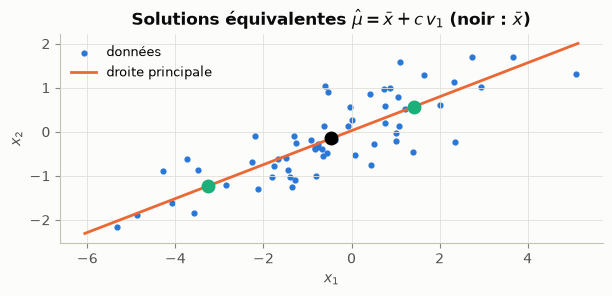

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
rng = np.random.RandomState(2)
X2 = rng.normal(size=(60, 2)) @ np.array([[2.0, 0.8], [0.0, 0.5]])
a2 = ns.acp(X2, 1)
v = a2["V"][:, 0]
ax.scatter(*X2.T, s=12, color=BLUE, label="données")
tt = np.linspace(-6, 6, 2)
ax.plot(X2.mean(0)[0] + tt * v[0], X2.mean(0)[1] + tt * v[1], color=ORANGE, label="droite principale")
for c in (-3.0, 0.0, 2.0):
    m = X2.mean(0) + c * v
    ax.plot(*m, "o", ms=9, color=COLORS[2] if c else "k")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Solutions équivalentes $\\hat\\mu = \\bar x + c\\, v_1$ (noir : $\\bar x$)")
ax.legend()
plt.show()

> **À retenir.** Dans (14.50), $\hat\lambda_i = \mathbf{V}_q^T(x_i - \hat\mu)$ (moindres carrés) et
> $\hat\mu$ est n'importe quel point du sous-espace affine $\bar x + \operatorname{Im}(\mathbf{V}_q)$ ;
> on choisit $\hat\mu = \bar x$ par commodité.

## Exercice 14.8 : Le problème de Procrustes, avec et sans échelle

**Énoncé.** Établir la solution (14.57) du problème de Procrustes
$\min_{\mu, \mathbf{R}} \|\mathbf{X}_2 - (\mathbf{X}_1\mathbf{R} + \mathbf{1}\mu^T)\|_F$ (14.56), avec
$\mathbf{R}$ orthogonale $p \times p$ ; puis celle du problème avec facteur d'échelle
$\min_{\beta, \mathbf{R}} \|\mathbf{X}_2 - \beta\mathbf{X}_1\mathbf{R}\|_F$ (14.58), $\beta > 0$.

### Rappels sur la norme de Frobenius

$\|\mathbf{A}\|_F^2 = \operatorname{tr}(\mathbf{A}^T\mathbf{A}) = \sum_{i,j} a_{ij}^2$. Elle est invariante
par multiplication par une matrice orthogonale : $\|\mathbf{A}\mathbf{R}\|_F^2 =
\operatorname{tr}(\mathbf{R}^T\mathbf{A}^T\mathbf{A}\mathbf{R}) = \operatorname{tr}(\mathbf{A}^T\mathbf{A}\mathbf{R}\mathbf{R}^T)
= \|\mathbf{A}\|_F^2$ (on a utilisé $\operatorname{tr}(\mathbf{B}\mathbf{C}) = \operatorname{tr}(\mathbf{C}\mathbf{B})$).

### Étape 1 : la translation

À $\mathbf{R}$ fixée, notons $\mathbf{E} = \mathbf{X}_2 - \mathbf{X}_1\mathbf{R}$, de lignes $e_i^T$. Le
critère vaut $\sum_i \|e_i - \mu\|^2$, minimal pour $\mu = \bar e$ (la moyenne minimise l'inertie,
cours 2), soit

$$\hat\mu = \bar x_2 - \mathbf{R}^T\bar x_1$$

(en vecteurs colonnes : la ligne moyenne de $\mathbf{X}_1\mathbf{R}$ est $\bar x_1^T\mathbf{R}$). Le livre
écrit $\hat\mu = \bar x_2 - \hat{\mathbf{R}}\bar x_1$ : c'est la même formule avec la convention où
les points sont transformés par $x \mapsto \mathbf{R}x$. Le critère devient alors
$\|\tilde{\mathbf{X}}_2 - \tilde{\mathbf{X}}_1\mathbf{R}\|_F^2$ avec les matrices centrées : on peut
oublier la translation.

### Étape 2 : la rotation

En développant et en utilisant l'invariance $\|\tilde{\mathbf{X}}_1\mathbf{R}\|_F = \|\tilde{\mathbf{X}}_1\|_F$ :

$$\|\tilde{\mathbf{X}}_2 - \tilde{\mathbf{X}}_1\mathbf{R}\|_F^2 = \|\tilde{\mathbf{X}}_2\|_F^2 + \|\tilde{\mathbf{X}}_1\|_F^2
 - 2\operatorname{tr}(\mathbf{R}^T\tilde{\mathbf{X}}_1^T\tilde{\mathbf{X}}_2).$$

Il faut **maximiser** $\operatorname{tr}(\mathbf{R}^T\mathbf{U}\mathbf{D}\mathbf{V}^T)$ où
$\tilde{\mathbf{X}}_1^T\tilde{\mathbf{X}}_2 = \mathbf{U}\mathbf{D}\mathbf{V}^T$ (SVD, $\mathbf{U}, \mathbf{V}$
orthogonales, $\mathbf{D} = \operatorname{diag}(d_1, \dots, d_p)$, $d_k \ge 0$). Par commutativité de
la trace, $\operatorname{tr}(\mathbf{R}^T\mathbf{U}\mathbf{D}\mathbf{V}^T) = \operatorname{tr}(\mathbf{Z}\mathbf{D})$ avec
$\mathbf{Z} = \mathbf{V}^T\mathbf{R}^T\mathbf{U}$, orthogonale (produit de matrices orthogonales).

Les coefficients d'une matrice orthogonale sont dans $[-1, 1]$ (ses colonnes sont unitaires),
donc

$$\operatorname{tr}(\mathbf{Z}\mathbf{D}) = \sum_k z_{kk} d_k \le \sum_k d_k = \operatorname{tr}(\mathbf{D}),$$

avec égalité si $\mathbf{Z} = \mathbf{I}$, c'est-à-dire $\mathbf{R}^T = \mathbf{V}\mathbf{U}^T$ :

$$\hat{\mathbf{R}} = \mathbf{U}\mathbf{V}^T \qquad (14.57).$$

La distance de Procrustes minimale vaut
$\sqrt{\|\tilde{\mathbf{X}}_1\|_F^2 + \|\tilde{\mathbf{X}}_2\|_F^2 - 2\operatorname{tr}(\mathbf{D})}$.

### Avec un facteur d'échelle (14.58)

On suppose les matrices centrées. À $\mathbf{R}$ fixée, le critère est un trinôme en $\beta$ :

$$\|\mathbf{X}_2 - \beta\mathbf{X}_1\mathbf{R}\|_F^2 = \|\mathbf{X}_2\|_F^2 - 2\beta\, t(\mathbf{R}) + \beta^2\|\mathbf{X}_1\|_F^2,
\qquad t(\mathbf{R}) = \operatorname{tr}(\mathbf{R}^T\mathbf{X}_1^T\mathbf{X}_2),$$

minimal en $\beta = t(\mathbf{R})/\|\mathbf{X}_1\|_F^2$ (si $t(\mathbf{R}) > 0$), où il vaut
$\|\mathbf{X}_2\|_F^2 - t(\mathbf{R})^2/\|\mathbf{X}_1\|_F^2$. Il faut donc maximiser $t(\mathbf{R})$ :
c'est le même problème qu'à l'étape 2, d'où le **même** $\hat{\mathbf{R}} = \mathbf{U}\mathbf{V}^T$, avec
$t(\hat{\mathbf{R}}) = \operatorname{tr}(\mathbf{D}) \ge 0$ et

$$\hat\beta = \frac{\operatorname{tr}(\mathbf{D})}{\|\mathbf{X}_1\|_F^2}.$$

### Vérification numérique

On compare notre solution à `scipy.linalg.orthogonal_procrustes` et à des matrices
orthogonales tirées au hasard.

In [5]:
rng = np.random.RandomState(0)
X1 = rng.normal(size=(40, 3))
Rvrai = np.linalg.qr(rng.normal(size=(3, 3)))[0]
X2 = 0.7 * X1 @ Rvrai + [1.0, -2.0, 0.5] + 0.05 * rng.normal(size=(40, 3))
res = ns.procrustes(X1, X2, echelle=True)
R_sp, _ = orthogonal_procrustes(X1 - X1.mean(0), X2 - X2.mean(0))
print("R identique à SciPy :", np.allclose(res["R"], R_sp))
print("beta estimé : %.4f (vrai : 0,7)" % res["beta"])
A1, A2 = X1 - X1.mean(0), X2 - X2.mean(0)
crit = lambda R, b: ((A2 - b * A1 @ R) ** 2).sum()
aleat = min(crit(Q, res["beta"]) for Q in (np.linalg.qr(rng.normal(size=(3, 3)))[0] for _ in range(5000)))
print("critère optimal %.4f ; meilleur de 5000 rotations aléatoires %.4f" % (crit(res["R"], res["beta"]), aleat))

R identique à SciPy : True
beta estimé : 0.6985 (vrai : 0,7)
critère optimal 0.2476 ; meilleur de 5000 rotations aléatoires 1.0042


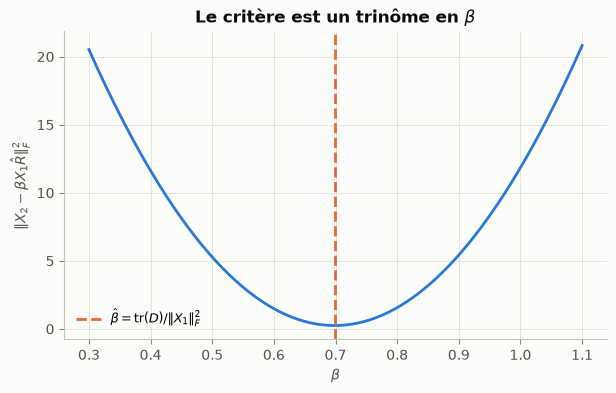

In [6]:
betas = np.linspace(0.3, 1.1, 100)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(betas, [crit(res["R"], b) for b in betas], color=BLUE)
ax.axvline(res["beta"], color=ORANGE, ls="--", label="$\\hat\\beta = \\mathrm{tr}(D)/\\|X_1\\|_F^2$")
ax.set_xlabel("$\\beta$")
ax.set_ylabel("$\\|X_2 - \\beta X_1 \\hat R\\|_F^2$")
ax.set_title("Le critère est un trinôme en $\\beta$")
ax.legend()
plt.show()

> **À retenir.** Procrustes : centrer les deux nuages, faire la SVD $\tilde{\mathbf{X}}_1^T\tilde{\mathbf{X}}_2 =
> \mathbf{U}\mathbf{D}\mathbf{V}^T$ ; la rotation optimale est $\mathbf{U}\mathbf{V}^T$, l'échelle optimale
> $\operatorname{tr}(\mathbf{D})/\|\tilde{\mathbf{X}}_1\|_F^2$. L'argument clé : la trace de $\mathbf{Z}\mathbf{D}$
> avec $\mathbf{Z}$ orthogonale est au plus $\operatorname{tr}(\mathbf{D})$.

## Exercice 14.9 : Moyenne de Procrustes avec facteurs d'échelle

**Énoncé.** Écrire un algorithme pour résoudre
$\min_{\{\beta_\ell, \mathbf{R}_\ell\}_1^L, \mathbf{M}} \sum_{\ell=1}^L \|\beta_\ell\mathbf{X}_\ell\mathbf{R}_\ell - \mathbf{M}\|_F^2$
(version avec échelle de (14.115)). L'appliquer aux trois « S » et comparer à la figure 14.26.

### Une contrainte est nécessaire

Sans contrainte, $\beta_\ell = 0$ et $\mathbf{M} = 0$ annulent le critère : solution triviale sans
intérêt. On impose donc la taille de la moyenne, par exemple $\|\mathbf{M}\|_F^2 = c^2$ avec
$c^2 = \frac1L\sum_\ell\|\mathbf{X}_\ell\|_F^2$ (taille moyenne des formes). Les formes sont
préalablement centrées (la translation se traite comme dans l'exercice 14.8).

### Algorithme alterné

1. **$\mathbf{M}$ fixée.** Le critère se sépare en $L$ problèmes indépendants
   $\min_{\beta_\ell, \mathbf{R}_\ell}\|\mathbf{M} - \beta_\ell\mathbf{X}_\ell\mathbf{R}_\ell\|_F^2$ : ce sont des
   problèmes de Procrustes avec échelle (exercice 14.8) ; avec $\mathbf{X}_\ell^T\mathbf{M} =
   \mathbf{U}_\ell\mathbf{D}_\ell\mathbf{V}_\ell^T$, $\mathbf{R}_\ell = \mathbf{U}_\ell\mathbf{V}_\ell^T$ et
   $\beta_\ell = \operatorname{tr}(\mathbf{D}_\ell)/\|\mathbf{X}_\ell\|_F^2$.
2. **$\beta_\ell, \mathbf{R}_\ell$ fixés.** Avec $\mathbf{A}_\ell = \beta_\ell\mathbf{X}_\ell\mathbf{R}_\ell$ et
   $\bar{\mathbf{A}} = \frac1L\sum_\ell \mathbf{A}_\ell$ :
   $\sum_\ell\|\mathbf{A}_\ell - \mathbf{M}\|_F^2 = \sum_\ell\|\mathbf{A}_\ell\|_F^2 - 2L\langle\bar{\mathbf{A}}, \mathbf{M}\rangle + Lc^2$
   sous $\|\mathbf{M}\|_F = c$. Par Cauchy-Schwarz, $\langle\bar{\mathbf{A}}, \mathbf{M}\rangle \le c\,\|\bar{\mathbf{A}}\|_F$,
   avec égalité pour $\mathbf{M} = c\,\bar{\mathbf{A}}/\|\bar{\mathbf{A}}\|_F$ : la **moyenne renormalisée**.

Chaque étape minimise exactement le critère par rapport à un bloc de variables : le critère
décroît à chaque itération et converge. C'est `ns.moyenne_procrustes(..., echelle=True)`.

### Application aux trois « S »

Les signatures du livre n'étant pas disponibles, on fabrique trois « S » de 96 points repères,
déformés, tournés, translatés et **de tailles différentes** (pour que l'échelle compte).

In [7]:
rng = np.random.RandomState(3)
echelles_vraies = [1.0, 1.6, 0.7]
trois_S = [b * ns.forme_s(rng=rng, deformation=0.08, bruit=0.02) @ ns.rotation2d(a) + c
           for b, a, c in zip(echelles_vraies, (0.0, 0.9, -0.6), ([0, 0], [4, 1], [-3, 2]))]
sans = ns.moyenne_procrustes(trois_S, echelle=False)
avec = ns.moyenne_procrustes(trois_S, echelle=True)
print("Facteurs d'échelle estimés beta_l       :", avec["beta"].round(3))
print("Produits beta_l x (échelle appliquée)_l :", (avec["beta"] * np.array(echelles_vraies)).round(3))

Facteurs d'échelle estimés beta_l       : [1.241 0.708 1.665]
Produits beta_l x (échelle appliquée)_l : [1.241 1.133 1.166]


Les produits $\hat\beta_\ell \times$ (échelle appliquée) sont à peu près constants : les
$\hat\beta_\ell$ compensent les tailles, à un facteur commun près fixé par la contrainte (les
petites différences viennent des déformations propres à chaque S, qui modifient aussi sa taille).

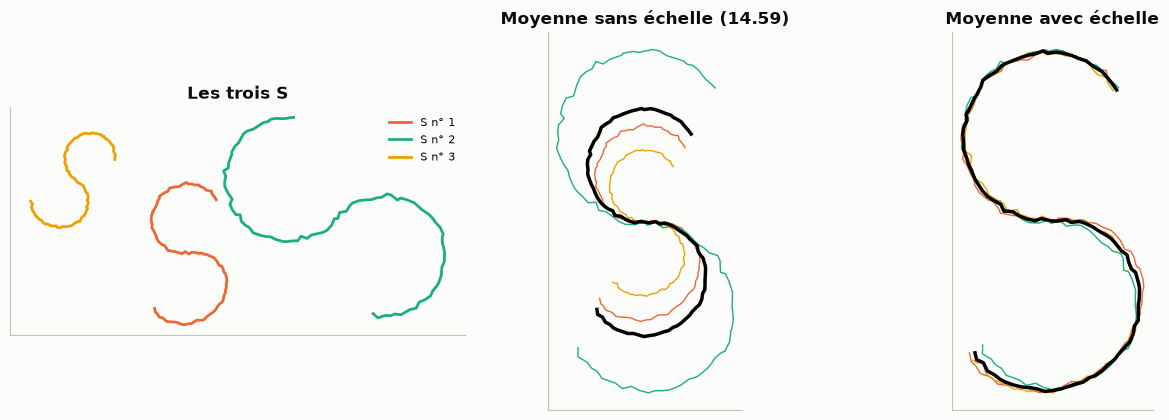

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for l, Sl in enumerate(trois_S):
    axes[0].plot(*Sl.T, "-", color=COLORS[l + 1], label="S n° %d" % (l + 1))
axes[0].set_title("Les trois S")
axes[0].legend(fontsize=8)
for ax, r, titre in ((axes[1], sans, "Moyenne sans échelle (14.59)"),
                     (axes[2], avec, "Moyenne avec échelle")):
    for l, Al in enumerate(r["alignees"]):
        ax.plot(*Al.T, "-", lw=1, color=COLORS[l + 1])
    ax.plot(*r["M"].T, "-", lw=2.5, color="k")
    ax.set_title(titre)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Sans échelle, les formes alignées gardent leurs tailles différentes et la moyenne est un
compromis flou ; avec échelle, les trois S se superposent bien et la moyenne est nette (comme sur
la figure 14.26, où les S du livre avaient des tailles voisines).

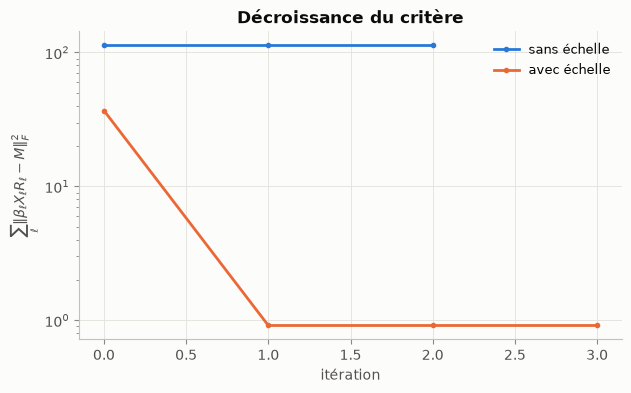

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sans["critere"], "o-", ms=3, color=BLUE, label="sans échelle")
ax.plot(avec["critere"], "o-", ms=3, color=ORANGE, label="avec échelle")
ax.set_yscale("log")
ax.set_xlabel("itération")
ax.set_ylabel("$\\sum_\\ell \\|\\beta_\\ell X_\\ell R_\\ell - M\\|_F^2$")
ax.set_title("Décroissance du critère")
ax.legend()
plt.show()

> **À retenir.** La moyenne de Procrustes avec échelle se calcule en alternant $L$ problèmes de
> Procrustes avec échelle et une moyenne renormalisée ; une contrainte sur la taille de
> $\mathbf{M}$ est indispensable pour éviter la solution nulle.

## Exercice 14.10 : Moyenne invariante par transformation affine

**Énoncé.** Établir la solution du problème
$\min_{\{\mathbf{A}_\ell\}_1^L, \mathbf{M}} \sum_\ell\|\mathbf{X}_\ell\mathbf{A}_\ell - \mathbf{M}\|_F^2$ (14.60),
où les $\mathbf{A}_\ell$ sont des matrices $p \times p$ inversibles et $\mathbf{M}^T\mathbf{M} = \mathbf{I}$.
L'appliquer aux trois S et comparer avec l'exercice 14.9.

### Solution

**$\mathbf{M}$ fixée.** Pour chaque $\ell$, $\min_{\mathbf{A}_\ell}\|\mathbf{X}_\ell\mathbf{A}_\ell - \mathbf{M}\|_F^2$ est
une régression multivariée par moindres carrés de $\mathbf{M}$ sur $\mathbf{X}_\ell$ (chaque colonne de
$\mathbf{M}$ est régressée sur les colonnes de $\mathbf{X}_\ell$, supposée de rang $p$) :

$$\hat{\mathbf{A}}_\ell = (\mathbf{X}_\ell^T\mathbf{X}_\ell)^{-1}\mathbf{X}_\ell^T\mathbf{M}, \qquad
\mathbf{X}_\ell\hat{\mathbf{A}}_\ell = \mathbf{H}_\ell\mathbf{M}, \quad
\mathbf{H}_\ell = \mathbf{X}_\ell(\mathbf{X}_\ell^T\mathbf{X}_\ell)^{-1}\mathbf{X}_\ell^T .$$

$\mathbf{H}_\ell$ est le projecteur orthogonal (de rang $p$) sur l'espace des colonnes de $\mathbf{X}_\ell$.

**Critère réduit.** Comme $\mathbf{I} - \mathbf{H}_\ell$ est aussi un projecteur,

$$\|\mathbf{M} - \mathbf{H}_\ell\mathbf{M}\|_F^2 = \operatorname{tr}(\mathbf{M}^T(\mathbf{I} - \mathbf{H}_\ell)\mathbf{M})
 = \operatorname{tr}(\mathbf{M}^T\mathbf{M}) - \operatorname{tr}(\mathbf{M}^T\mathbf{H}_\ell\mathbf{M})
 = p - \operatorname{tr}(\mathbf{M}^T\mathbf{H}_\ell\mathbf{M}).$$

En sommant : $\sum_\ell \|\cdot\|^2 = Lp - L\operatorname{tr}(\mathbf{M}^T\bar{\mathbf{H}}\mathbf{M})$ avec
$\bar{\mathbf{H}} = \frac1L\sum_\ell\mathbf{H}_\ell$ (symétrique). Il faut maximiser
$\operatorname{tr}(\mathbf{M}^T\bar{\mathbf{H}}\mathbf{M})$ sous $\mathbf{M}^T\mathbf{M} = \mathbf{I}_p$ : par le
lemme, $\mathbf{M}$ est formée des $p$ **premiers vecteurs propres** de $\bar{\mathbf{H}}$. Aucune
itération n'est nécessaire.

> **Remarques.** (i) On centre les $\mathbf{X}_\ell$ au préalable (ou on ajoute une colonne de 1) pour
> tenir compte des translations. (ii) $\mathbf{M}$ n'est définie qu'à une transformation orthogonale
> près (toute base orthonormée du même sous-espace propre convient), et elle est
> « blanchie » ($\mathbf{M}^T\mathbf{M} = \mathbf{I}$) : sa forme se compare à une autre moyenne via
> une transformation affine. (iii) Les valeurs propres de $\bar{\mathbf{H}}$ sont dans $[0, 1]$ et
> valent 1 si les $L$ formes sont exactement affinement équivalentes.

In [10]:
aff = ns.moyenne_affine(trois_S)
print("Valeurs propres de Hbar (les 4 premières) :", aff["valeurs_propres"][:4].round(4))

Valeurs propres de Hbar (les 4 premières) : [9.998e-01 9.980e-01 1.700e-03 3.000e-04]


Les deux premières valeurs propres sont proches de 1 : les trois S sont presque affinement
équivalents, et la troisième, proche de 0, montre que l'espace « commun » est bien de dimension 2.
Pour comparer avec la moyenne de Procrustes de l'exercice 14.9, on aligne $\mathbf{M}_{\text{aff}}$ sur
$\mathbf{M}_{\text{Proc}}$ par une transformation affine (moindres carrés).

In [11]:
B, *_ = np.linalg.lstsq(aff["M"], avec["M"], rcond=None)
M_aff_aligne = aff["M"] @ B
ecart = np.sqrt(((M_aff_aligne - avec["M"]) ** 2).sum() / (avec["M"] ** 2).sum())
print("Écart relatif entre les deux moyennes après alignement affine : %.3f" % ecart)

Écart relatif entre les deux moyennes après alignement affine : 0.001


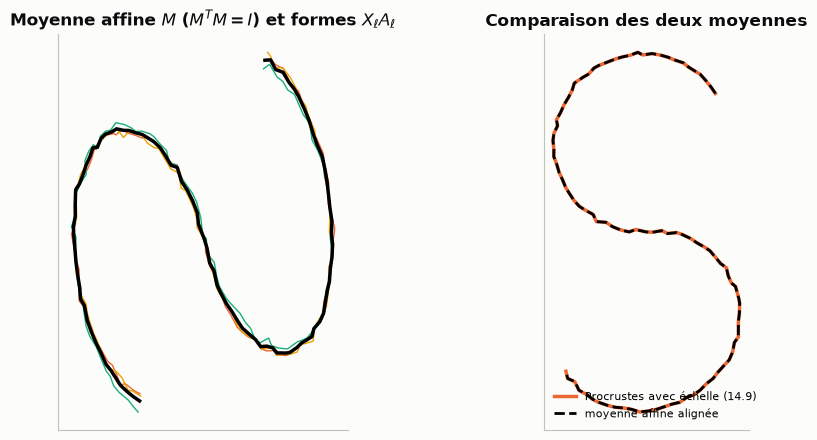

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for l, Al in enumerate(aff["alignees"]):
    axes[0].plot(*Al.T, "-", lw=1, color=COLORS[l + 1])
axes[0].plot(*aff["M"].T, "-", lw=2.5, color="k")
axes[0].set_title("Moyenne affine $M$ ($M^TM = I$) et formes $X_\\ell A_\\ell$")
axes[1].plot(*avec["M"].T, "-", lw=2.5, color=ORANGE, label="Procrustes avec échelle (14.9)")
axes[1].plot(*M_aff_aligne.T, "--", lw=2, color="k", label="moyenne affine alignée")
axes[1].set_title("Comparaison des deux moyennes")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Les deux moyennes sont très proches : ici les différences entre les S sont surtout des
similitudes (rotation, échelle, translation), cas particulier des transformations affines. La
moyenne affine absorbe en plus les cisaillements et étirements anisotropes.

> **À retenir.** La moyenne invariante affine s'obtient sans itération : $\mathbf{M}$ = les $p$ premiers
> vecteurs propres de la moyenne des projecteurs $\mathbf{H}_\ell$, et
> $\mathbf{A}_\ell = (\mathbf{X}_\ell^T\mathbf{X}_\ell)^{-1}\mathbf{X}_\ell^T\mathbf{M}$.

## Exercice 14.11 : Positionnement multidimensionnel classique

**Énoncé.** Soit $\mathbf{S}$ la matrice des produits scalaires centrés, $s_{ij} = \langle x_i - \bar x,
x_j - \bar x\rangle$. Soient $\lambda_1 > \dots > \lambda_k$ ses $k$ plus grandes valeurs propres,
$\mathbf{E}_k = (e_1, \dots, e_k)$ les vecteurs propres associés et $\mathbf{D}_k =
\operatorname{diag}(\sqrt{\lambda_1}, \dots, \sqrt{\lambda_k})$. Montrer que les solutions $z_i$ du
problème d'échelle classique (14.100) sont les lignes de $\mathbf{E}_k\mathbf{D}_k$.

### Le problème

On cherche $z_1, \dots, z_N \in \mathbb{R}^k$ minimisant

$$S_C(z) = \sum_{i,i'}\big(s_{ii'} - \langle z_i - \bar z, z_{i'} - \bar z\rangle\big)^2 \qquad (14.100).$$

Notons $\tilde{\mathbf{Z}}$ la matrice $N \times k$ des $z_i - \bar z$. Alors
$S_C = \|\mathbf{S} - \tilde{\mathbf{Z}}\tilde{\mathbf{Z}}^T\|_F^2$ : on cherche la meilleure approximation
de $\mathbf{S}$ par une matrice $\mathbf{B} = \tilde{\mathbf{Z}}\tilde{\mathbf{Z}}^T$, symétrique positive de
rang au plus $k$.

### Propriétés de $\mathbf{S}$

Avec $\tilde{\mathbf{X}}$ la matrice des $x_i - \bar x$, $\mathbf{S} = \tilde{\mathbf{X}}\tilde{\mathbf{X}}^T$ :
elle est symétrique et positive ($u^T\mathbf{S}u = \|\tilde{\mathbf{X}}^Tu\|^2 \ge 0$), donc
diagonalisable en base orthonormée avec des valeurs propres $\lambda_j \ge 0$. De plus
$\mathbf{S}\mathbf{1} = \tilde{\mathbf{X}}(\tilde{\mathbf{X}}^T\mathbf{1}) = 0$ car les colonnes de
$\tilde{\mathbf{X}}$ sont centrées : $\mathbf{1}$ est vecteur propre de valeur propre 0, et les vecteurs
propres $e_j$ de valeur propre $\lambda_j > 0$ lui sont orthogonaux ($\mathbf{1}^Te_j = 0$).

### Solution

**Théorème d'Eckart-Young** (déjà utilisé pour l'ACP, section 14.5.1) : pour toute matrice
$\mathbf{S}$ et tout rang $k$, la meilleure approximation de $\mathbf{S}$ en norme de Frobenius par une
matrice de rang $\le k$ est sa SVD tronquée. Pour $\mathbf{S}$ symétrique positive, la SVD est la
décomposition spectrale, d'où la meilleure approximation

$$\mathbf{B}^* = \sum_{j=1}^k \lambda_j e_je_j^T = \mathbf{E}_k\mathbf{D}_k^2\mathbf{E}_k^T
 = (\mathbf{E}_k\mathbf{D}_k)(\mathbf{E}_k\mathbf{D}_k)^T .$$

$\mathbf{B}^*$ est elle-même de la forme $\mathbf{Z}\mathbf{Z}^T$ avec $\mathbf{Z} = \mathbf{E}_k\mathbf{D}_k$ :
le minimum sur toutes les matrices de rang $\le k$ est atteint dans la classe plus petite des
$\tilde{\mathbf{Z}}\tilde{\mathbf{Z}}^T$, c'est donc aussi le minimum sur cette classe. Enfin les colonnes
de $\mathbf{Z} = \mathbf{E}_k\mathbf{D}_k$ sont orthogonales à $\mathbf{1}$, donc $\bar z = 0$ et
$\tilde{\mathbf{Z}} = \mathbf{Z}$ : les $z_i$ optimaux sont les lignes de $\mathbf{E}_k\mathbf{D}_k$, et
$\min S_C = \sum_{j > k}\lambda_j^2$. (Toute rotation $\mathbf{Z}\mathbf{Q}$, $\mathbf{Q}$ orthogonale, est
aussi solution.) $\square$

> **Remarque.** Pour des données euclidiennes, $\mathbf{S} = \tilde{\mathbf{X}}\tilde{\mathbf{X}}^T =
> \mathbf{U}\mathbf{D}^2\mathbf{U}^T$ (SVD de $\tilde{\mathbf{X}}$) donc $\mathbf{E}_k\mathbf{D}_k = \mathbf{U}_k\mathbf{D}_k$ :
> l'échelle classique redonne les **composantes principales**. À partir des seules distances,
> on reconstruit $\mathbf{S} = -\frac12\mathbf{J}\mathbf{D}^{(2)}\mathbf{J}$ par double centrage, car
> $\|x_i - x_j\|^2 = s_{ii} + s_{jj} - 2s_{ij}$.

### Vérification numérique

In [13]:
rng = np.random.RandomState(0)
Xm = rng.normal(size=(30, 5)) * [3, 2, 1, 0.5, 0.2]
Xt = Xm - Xm.mean(0)
S_mat = Xt @ Xt.T
Z, vals = ns.mds_classique(S_mat, 2, similarites=True)
Sc = lambda Z_: ((S_mat - (Z_ - Z_.mean(0)) @ (Z_ - Z_.mean(0)).T) ** 2).sum()
print("S_C(E_k D_k) = %.4f ; somme des lambda_j^2 pour j > 2 = %.4f" % (Sc(Z), (vals[2:] ** 2).sum()))
print("Meilleur S_C sur 3000 configurations perturbées : %.4f"
      % min(Sc(Z + 0.05 * rng.normal(size=Z.shape)) for _ in range(3000)))
print("Égal aux composantes principales (au signe près) :",
      np.allclose(np.abs(Z), np.abs(ns.acp(Xm, 2)["scores"])))

S_C(E_k D_k) = 601.8454 ; somme des lambda_j^2 pour j > 2 = 601.8454


Meilleur S_C sur 3000 configurations perturbées : 630.5068
Égal aux composantes principales (au signe près) : True


Une descente de gradient sur $S_C$ depuis une configuration aléatoire converge aussi vers la
valeur $\sum_{j>k}\lambda_j^2$ : $\nabla_{\mathbf{Z}} \|\mathbf{S} - \mathbf{Z}\mathbf{Z}^T\|_F^2 =
-4(\mathbf{S} - \mathbf{Z}\mathbf{Z}^T)\mathbf{Z}$ (pour $\mathbf{Z}$ centrée).

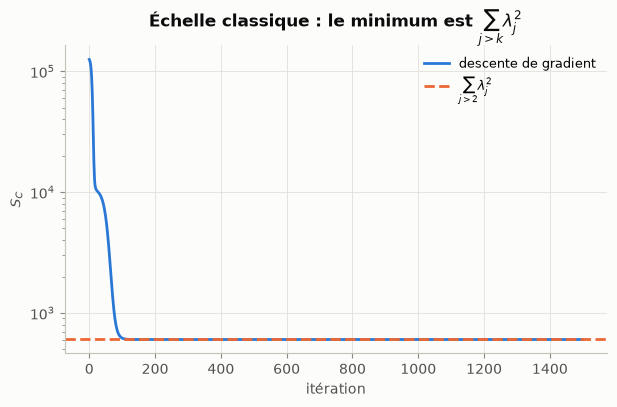

In [14]:
Zg = rng.normal(size=(30, 2))
pas = 0.05 / vals[0]                     # pas adapté à la plus grande valeur propre
histo = []
for _ in range(1500):
    Zg = Zg - Zg.mean(0)
    Zg += pas * 4 * (S_mat - Zg @ Zg.T) @ Zg
    histo.append(Sc(Zg))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(histo, color=BLUE, label="descente de gradient")
ax.axhline((vals[2:] ** 2).sum(), color=ORANGE, ls="--", label="$\\sum_{j>2} \\lambda_j^2$")
ax.set_yscale("log")
ax.set_xlabel("itération")
ax.set_ylabel("$S_C$")
ax.set_title("Échelle classique : le minimum est $\\sum_{j>k}\\lambda_j^2$")
ax.legend()
plt.show()

> **À retenir.** L'échelle classique est une approximation de rang $k$ de la matrice des produits
> scalaires centrés : la solution est donnée par les $k$ premiers vecteurs propres, mis à
> l'échelle par la racine des valeurs propres ; sur des données euclidiennes, ce sont les
> composantes principales.

## Exercice 14.12 : ACP parcimonieuse : les deux étapes de l'algorithme

**Énoncé.** On considère le critère (14.71) :
$\sum_i\|x_i - \Theta\mathbf{V}^Tx_i\|_2^2 + \lambda\sum_k\|v_k\|_2^2 + \sum_k\lambda_{1k}\|v_k\|_1$ sous
$\Theta^T\Theta = \mathbf{I}_K$, où $\mathbf{V}$ et $\Theta$ sont $p \times K$.

1. Montrer qu'à $\Theta$ fixé, résoudre en $\mathbf{V}$ revient à $K$ problèmes elastic net séparés,
   de réponses les $K$ composantes de $\Theta^Tx_i$.
2. Montrer qu'à $\mathbf{V}$ fixé, résoudre en $\Theta$ est une version de rang réduit du problème de
   Procrustes, qui se ramène à $\max_\Theta\operatorname{tr}(\Theta^T\mathbf{M})$ sous
   $\Theta^T\Theta = \mathbf{I}_K$ (14.116), où $\mathbf{M}$ est $p \times K$ ; si $\mathbf{M} =
   \mathbf{U}\mathbf{D}\mathbf{Q}^T$ (SVD), montrer que $\Theta = \mathbf{U}\mathbf{Q}^T$.

### Écriture matricielle

Les $x_i^T$ sont les lignes de $\mathbf{X}$ ($N \times p$, centrée). La ligne $i$ de
$\mathbf{X}\mathbf{V}\Theta^T$ est $x_i^T\mathbf{V}\Theta^T = (\Theta\mathbf{V}^Tx_i)^T$, donc

$$\sum_i\|x_i - \Theta\mathbf{V}^Tx_i\|^2 = \|\mathbf{X} - \mathbf{X}\mathbf{V}\Theta^T\|_F^2 .$$

### 1. $\Theta$ fixé : $K$ régressions elastic net

Complétons $\Theta$ en une matrice orthogonale $p \times p$ $[\Theta, \Theta_\perp]$ (on prolonge la
famille orthonormée des colonnes de $\Theta$ en une base orthonormée). La norme de Frobenius étant
invariante par multiplication à droite par une matrice orthogonale,

$$\|\mathbf{X} - \mathbf{X}\mathbf{V}\Theta^T\|_F^2 = \|(\mathbf{X} - \mathbf{X}\mathbf{V}\Theta^T)[\Theta, \Theta_\perp]\|_F^2
= \|\mathbf{X}\Theta - \mathbf{X}\mathbf{V}\|_F^2 + \|\mathbf{X}\Theta_\perp\|_F^2,$$

car $\Theta^T\Theta = \mathbf{I}$ et $\Theta^T\Theta_\perp = 0$. Le second terme ne dépend pas de
$\mathbf{V}$, et le premier se découpe colonne par colonne.

À une constante près, le critère vaut donc

$$\sum_{k=1}^K\Big[\|\mathbf{X}\theta_k - \mathbf{X}v_k\|^2 + \lambda\|v_k\|_2^2 + \lambda_{1k}\|v_k\|_1\Big],$$

somme de $K$ termes dépendant chacun d'un seul $v_k$ : on les minimise séparément. Chacun est une
**régression elastic net** (pénalités ridge et lasso combinées, section 18.4) de la réponse
$y^{(k)} = \mathbf{X}\theta_k$, dont la composante $i$ est $\theta_k^Tx_i$, c'est-à-dire la $k$-ième
composante de $\Theta^Tx_i$, sur les variables $\mathbf{X}$. $\square$

### 2. $\mathbf{V}$ fixé : Procrustes de rang réduit

Les pénalités ne dépendent pas de $\Theta$. On développe, avec $\mathbf{B} = \mathbf{X}\mathbf{V}$ :

$$\|\mathbf{X} - \mathbf{B}\Theta^T\|_F^2 = \|\mathbf{X}\|_F^2 - 2\operatorname{tr}(\mathbf{X}^T\mathbf{B}\Theta^T)
 + \operatorname{tr}(\Theta\mathbf{B}^T\mathbf{B}\Theta^T).$$

Le dernier terme vaut $\operatorname{tr}(\mathbf{B}^T\mathbf{B}\Theta^T\Theta) = \operatorname{tr}(\mathbf{B}^T\mathbf{B})$,
indépendant de $\Theta$. Il reste à **maximiser** $\operatorname{tr}(\mathbf{X}^T\mathbf{X}\mathbf{V}\Theta^T)
= \operatorname{tr}(\Theta^T\mathbf{M})$ avec $\mathbf{M} = \mathbf{X}^T\mathbf{X}\mathbf{V}$ ($p \times K$) : c'est
(14.116).

Soit $\mathbf{M} = \mathbf{U}\mathbf{D}\mathbf{Q}^T$ la SVD réduite ($\mathbf{U}$ : $p \times K$ à colonnes
orthonormées, $\mathbf{D} = \operatorname{diag}(d_k)$, $d_k \ge 0$, $\mathbf{Q}$ : $K \times K$ orthogonale).
Alors

$$\operatorname{tr}(\Theta^T\mathbf{U}\mathbf{D}\mathbf{Q}^T) = \operatorname{tr}(\mathbf{Q}^T\Theta^T\mathbf{U}\mathbf{D})
 = \sum_k d_k\,(\Theta q_k)^Tu_k \le \sum_k d_k,$$

car $\Theta q_k$ et $u_k$ sont unitaires ($\|\Theta q_k\|^2 = q_k^T\Theta^T\Theta q_k = 1$) et, par
Cauchy-Schwarz, $(\Theta q_k)^Tu_k \le 1$. L'égalité a lieu si $\Theta q_k = u_k$ pour tout $k$,
soit $\Theta\mathbf{Q} = \mathbf{U}$, c'est-à-dire $\Theta = \mathbf{U}\mathbf{Q}^T$, qui vérifie bien
$\Theta^T\Theta = \mathbf{Q}\mathbf{U}^T\mathbf{U}\mathbf{Q}^T = \mathbf{I}_K$. $\square$

### Vérifications numériques

**(a)** L'étape $\mathbf{V}$ : notre elastic net par descente de coordonnées (fonction
`ns.elastic_net`) donne le même critère que la minimisation directe de (14.71) en $\mathbf{V}$ (par
`scipy.optimize`).

In [15]:
from scipy.optimize import minimize

rng = np.random.RandomState(0)
Xs = rng.normal(size=(80, 6)) @ rng.normal(size=(6, 6))
Xs -= Xs.mean(0)
K, lam2, lam1 = 2, 1.0, 20.0
Theta = np.linalg.qr(rng.normal(size=(6, K)))[0]
V_en = np.column_stack([ns.elastic_net(Xs, Xs @ Theta[:, k], lam2, lam1) for k in range(K)])


def critere_1471(Vflat):
    Vm = Vflat.reshape(6, K)
    return ((Xs - Xs @ Vm @ Theta.T) ** 2).sum() + lam2 * (Vm ** 2).sum() + lam1 * np.abs(Vm).sum()


direct = minimize(critere_1471, np.zeros(6 * K), method="Powell", options={"maxiter": 50000, "xtol": 1e-8, "ftol": 1e-12})
print("critère : elastic net séparés %.5f ; minimisation directe %.5f" % (critere_1471(V_en.ravel()), direct.fun))

critère : elastic net séparés 2656.89589 ; minimisation directe 2657.09353


**(b)** L'étape $\Theta$ : $\Theta = \mathbf{U}\mathbf{Q}^T$ donne une trace supérieure à celle de toute
matrice à colonnes orthonormées tirée au hasard.

In [ ]:
Mmat = Xs.T @ Xs @ V_en
Th = ns.procrustes_reduit(Mmat)
meilleur_hasard = max(np.trace(Q.T @ Mmat) for Q in (np.linalg.qr(rng.normal(size=(6, K)))[0] for _ in range(5000)))
print("tr(Theta^T M) : formule %.3f ; meilleur de 5000 tirages %.3f ; somme des d_k %.3f"
      % (np.trace(Th.T @ Mmat), meilleur_hasard, np.linalg.svd(Mmat, compute_uv=False).sum()))